# Exploratory Data Analysis (EDA) with Pandas — Beginner Guide

**What you will learn in this notebook**

1. The steps of a Data Analysis (DA) workflow — the big picture
2. What EDA is and why every analyst does it first
3. A repeatable **EDA checklist**, step by step, with code

**Dataset:** `Employee_Master` sheet from `Employee_Pandas_Master_Workbook.xlsx` (the same employee data we used in the Pandas notebook).

# Part 1 — The Data Analysis Workflow

Every data project, small or big, follows the same journey:

```
 1. ASK  →  2. COLLECT  →  3. CLEAN  →  4. EXPLORE (EDA)  →  5. ANALYZE  →  6. COMMUNICATE
```

| # | Step | Question it answers | Excel you already know | Our employee example |
|---|------|--------------------|------------------------|----------------------|
| 1 | **Problem Statement** (define the problem) | What do we want to find out? | — | *"How are salaries spread across departments and grades?"* |
| 2 | **Collect** (get the data) | Where is the data? | Open workbook / import CSV | `pd.read_excel(...)` |
| 3 | **Clean** (prepare) | Can we trust this data? | Remove Duplicates, Find & Replace, TRIM | `drop_duplicates()`, `fillna()`, `str.strip()` |
| 4 | **Explore** (**EDA**) | What does the data look like? Any patterns? | Filters, Pivot Tables, quick charts | `describe()`, `value_counts()`, `hist()`, `boxplot()` |
| 5 | **Analyze** (go deeper) | Why is it happening? Can we predict it? | Formulas, What-If | Statistics, tests, machine learning |
| 6 | **Communicate** (share) | What should the decision-maker do? | Charts, Dashboard, Report | Final charts + 3 key insights |

### Three things to remember
- It is a **loop, not a straight line.** While exploring you often find new errors and go back to cleaning.
- **Steps 3 and 4 take most of an analyst's time** (often 60–70%).
- **EDA sits in the middle** — it connects clean data to real answers.

# Part 2 — What is EDA?

**EDA (Exploratory Data Analysis) = getting to know your data *before* you draw conclusions.**

> Think of cooking: before you cook, you check the ingredients — are they fresh, how much do you have, is anything missing? EDA is that check for data.

### Why do EDA?
| Reason | Example |
|--------|---------|
| Catch errors early | Duplicate employee, missing salary |
| Understand each column | Is salary evenly spread or are a few people very high? |
| Find patterns & relationships | Do more experienced employees earn more? |
| Decide what to do next | Which columns are useful for the final analysis? |

### Two kinds of columns (this decides which chart you use)
| Type | Meaning | Examples in our data | Typical tools |
|------|---------|---------------------|---------------|
| **Numerical** | Numbers you can add/average | `Monthly_Salary`, `Tenure_Years` | `describe()`, histogram, box plot |
| **Categorical** | Labels / groups | `Department`, `Grade`, `Gender` | `value_counts()`, count plot, bar chart |

### Three levels of EDA
| Level | Looks at | Example question |
|-------|----------|-----------------|
| **Univariate** | One column | What is the typical salary? |
| **Bivariate** | Two columns | Does salary change with department? |
| **Multivariate** | Three or more | How do salary, tenure and grade move together? |

### Our EDA Roadmap (we follow this order in the notebook)
| Step | What we do | Main code |
|------|-----------|-----------|
| 1 | Load the data | `pd.read_excel()` |
| 2 | First look | `head()`, `shape`, `info()`, `describe()` |
| 3 | Check data quality | `isna()`, `duplicated()`, `unique()` |
| 4 | Clean & prepare | `drop_duplicates()`, `fillna()`, `replace()`, new columns |
| 5 | Univariate — numbers | `hist`, `boxplot`, mean vs median |
| 6 | Univariate — categories | `value_counts()`, `countplot` |
| 7 | Bivariate — two columns | `groupby`, `boxplot`, `scatterplot`, `crosstab` |
| 8 | Find outliers | IQR rule |
| 9 | Correlation | `corr()`, heatmap |
| 10 | Insights & save | summary + `to_csv()` |

# Setup — Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")          # clean chart style
plt.rcParams["figure.figsize"] = (8, 4)   # default chart size

print("pandas version:", pd.__version__)

pandas version: 3.0.6


# Step 1 — Load the Data

**Why?** Every analysis starts by getting the data into a DataFrame.
**Excel equivalent:** File → Open.

Change `file_path` to where the workbook is saved on **your** computer.

In [2]:
#Change this path to your own file location
# Example: file_path = r"D:\DA With Python LH\Python\Input_Folder\04Employee_Pandas_Master_Workbook.xlsx"
file_path = r"D:\DA With Python LH\Python\Input_Folder\Employee_Pandas_Master_Workbook.xlsx"
df = pd.read_excel(file_path, sheet_name="Employee_Master")
df.head()

,Employee_ID,Employee_Name,Gender,Department,Grade,City,Join_Date,Monthly_Salary,Employment_Type,Email,Manager_ID
0,1001,Amit Sharma,Male,Operations,G1,Delhi,2021-04-05,38000.0,Part Time,amit.sharma@example.com,NaN
1,1002,Sara Khan,Male,IT,G1,Pune,2018-01-03,43000.0,Full Time,sara.khan@example.com,NaN
2,1003,John D'Souza,Female,Sales,G2,Nagpur,2024-04-15,65000.0,Part Time,john.dsouza@example.com,NaN
3,1004,Meena Iyer,Female,Marketing,G3,Mumbai,2022-03-07,75000.0,Full Time,meena.iyer@example.com,NaN
4,1005,Ravi Patel,Female,Sales,G2,Hyderabad,2022-01-24,56000.0,Full Time,ravi.patel@example.com,NaN


# Step 2 — First Look at the Data

**Why?** Before any analysis, answer the basic questions: *How big is it? What columns? What types? Any obvious problems?*

| Code | Tells you |
|------|-----------|
| `df.head()` / `df.tail()` | First / last rows — does it look right? |
| `df.shape` | (rows, columns) |
| `df.info()` | Column names, data types, non-null counts |
| `df.describe()` | Min, max, mean, quartiles |

In [3]:
display(df.head())
display(df.tail())

print("Rows, Columns :", df.shape)
print("Column names  :", df.columns.tolist())
print()
df.info()

,Employee_ID,Employee_Name,Gender,Department,Grade,City,Join_Date,Monthly_Salary,Employment_Type,Email,Manager_ID
0,1001,Amit Sharma,Male,Operations,G1,Delhi,2021-04-05,38000.0,Part Time,amit.sharma@example.com,NaN
1,1002,Sara Khan,Male,IT,G1,Pune,2018-01-03,43000.0,Full Time,sara.khan@example.com,NaN
2,1003,John D'Souza,Female,Sales,G2,Nagpur,2024-04-15,65000.0,Part Time,john.dsouza@example.com,NaN
3,1004,Meena Iyer,Female,Marketing,G3,Mumbai,2022-03-07,75000.0,Full Time,meena.iyer@example.com,NaN
4,1005,Ravi Patel,Female,Sales,G2,Hyderabad,2022-01-24,56000.0,Full Time,ravi.patel@example.com,NaN


,Employee_ID,Employee_Name,Gender,Department,Grade,City,Join_Date,Monthly_Salary,Employment_Type,Email,Manager_ID
26,1027,Tanvi Desai,Male,Marketing,G1,Pune,2025-04-13,45000.0,Full Time,tanvi.desai@example.com,1004.0
27,1028,Aditya Bose,Female,Finance,G4,Pune,2022-07-23,119000.0,Full Time,aditya.bose@example.com,1002.0
28,1029,Sreya Jain,Male,Sales,G2,Mumbai,2018-12-11,62000.0,Full Time,sreya.jain@example.com,1005.0
29,1030,Omkar Kale,Male,IT,G1,Delhi,2020-02-20,32000.0,Part Time,omkar.kale@example.com,1004.0
30,1003,John D'Souza,Female,Sales,G2,Nagpur,2024-04-15,65000.0,Part Time,john.dsouza@example.com,NaN


Rows, Columns : (31, 11)
Column names  : ['Employee_ID', 'Employee_Name', 'Gender', 'Department', 'Grade', 'City', 'Join_Date', 'Monthly_Salary', 'Employment_Type', 'Email', 'Manager_ID']

<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Employee_ID      31 non-null     int64         
 1   Employee_Name    31 non-null     str           
 2   Gender           31 non-null     str           
 3   Department       31 non-null     str           
 4   Grade            31 non-null     str           
 5   City             31 non-null     str           
 6   Join_Date        31 non-null     datetime64[us]
 7   Monthly_Salary   30 non-null     float64       
 8   Employment_Type  31 non-null     str           
 9   Email            31 non-null     str           
 10  Manager_ID       23 non-null     float64       
dtypes: datetime64[us](1), flo

In [4]:
# Summary of NUMBER columns, then TEXT / CATEGORY columns
display(df.describe())
display(df.describe(exclude="number"))

,Employee_ID,Join_Date,Monthly_Salary,Manager_ID
count,31.000000,31,30.000000,23.000000
mean,1015.096774,2022-06-03 13:09:40.645161,60066.666667,1004.478261
min,1001.000000,2018-01-03 00:00:00,31000.000000,1001.000000
25%,1007.500000,2019-09-09 00:00:00,38250.000000,1003.000000
50%,1015.000000,2022-12-22 00:00:00,57000.000000,1005.000000
75%,1022.500000,2024-08-01 12:00:00,68000.000000,1006.000000
max,1030.000000,2025-12-02 00:00:00,123000.000000,1007.000000
std,8.941867,NaN,25690.375675,1.879786


,Employee_Name,Gender,Department,Grade,City,Join_Date,Employment_Type,Email
count,31,31,31,31,31,31,31,31
unique,30,2,7,4,8,NaN,3,30
top,John D'Souza,Male,Sales,G1,Pune,NaN,Full Time,john.dsouza@example.com
freq,2,17,9,12,8,NaN,20,2
mean,NaN,NaN,NaN,NaN,NaN,2022-06-03 13:09:40.645161,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,2018-01-03 00:00:00,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,2019-09-09 00:00:00,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,2022-12-22 00:00:00,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,2024-08-01 12:00:00,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN,2025-12-02 00:00:00,NaN,NaN


**How to read the output:**
- `info()` → compare *Non-Null Count* with the total rows. Fewer = **missing data**. Also check the *Dtype* (is `Join_Date` a date?).
- `describe()` → look at `min` / `max` (a salary of 0? a huge value?) and `unique` (more departments than expected?).

###  TRY TO FIND
1. How many rows and columns are in the data?
2. Which columns have missing values?
3. How many unique departments are there?

# Step 3 — Check Data Quality

**Why?** Wrong data gives wrong answers ("garbage in, garbage out"). Before fixing anything, **find** the problems first.

| # | Problem | How we find it |
|---|---------|----------------|
| 3.1 | Missing values | `isna().sum()` |
| 3.2 | Duplicate rows | `duplicated()` |
| 3.3 | Inconsistent categories (`Mktg` vs `Marketing`, extra spaces) | `unique()` |

### 3.1 Missing values
**Excel equivalent:** filtering for blanks.

In [5]:
# Count and percentage of missing values in each column
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(1)
}).sort_values("missing_count", ascending=False)

missing

,missing_count,missing_percent
Manager_ID,8,25.8
Monthly_Salary,1,3.2
Employee_ID,0,0.0
Gender,0,0.0
Employee_Name,0,0.0
Department,0,0.0
Grade,0,0.0
Join_Date,0,0.0
City,0,0.0
Employment_Type,0,0.0


**Think before you fix** — a missing value is not always an error:
- `Monthly_Salary` missing → **a real gap**, we should fill it.
- `Manager_ID` missing → may simply mean *that person has no manager* (top of the hierarchy). Not an error!

### 3.2 Duplicate rows
**Excel equivalent:** Data → Remove Duplicates (but first just *look*).

In [6]:
# Fully identical rows
print("Fully duplicate rows:", df.duplicated().sum())

# Same Employee_ID appearing twice (an ID should be unique!)
print("Repeated Employee_IDs:", df["Employee_ID"].duplicated().sum())

# Show every row that is part of a duplicate pair
df[df["Employee_ID"].duplicated(keep=False)]

Fully duplicate rows: 1
Repeated Employee_IDs: 1


,Employee_ID,Employee_Name,Gender,Department,Grade,City,Join_Date,Monthly_Salary,Employment_Type,Email,Manager_ID
2,1003,John D'Souza,Female,Sales,G2,Nagpur,2024-04-15,65000.0,Part Time,john.dsouza@example.com,NaN
30,1003,John D'Souza,Female,Sales,G2,Nagpur,2024-04-15,65000.0,Part Time,john.dsouza@example.com,NaN


### 3.3 Inconsistent categories
The same thing written in different ways is counted as **different groups** — this breaks `groupby` and charts.

In [7]:
# Print the unique values of each text column.  The quotes help us see extra spaces!
for col in ["Department", "Gender", "Grade", "Employment_Type", "City"]:
    print(f"{col:16} →", df[col].unique().tolist())

Department       → ['Operations', 'IT', 'Sales', 'Marketing', 'HR', 'Mktg', 'Finance']
Gender           → ['Male', 'Female']
Grade            → ['G1', 'G2', 'G3', 'G4']
Employment_Type  → ['Part Time', 'Full Time', 'Contract']
City             → ['Delhi', 'Pune', 'Nagpur', 'Mumbai', 'Hyderabad', ' pune ', 'Chennai', 'Bengaluru']


**Look for:** names that mean the same thing but are spelled differently (`Mktg` / `Marketing`) or values with hidden spaces (`' Sales'`).

###  Your turn — write your Data Quality Report
| Problem found | Column | How many? |
|---|---|---|
| Missing values | | |
| Duplicate rows | | |
| Inconsistent category | | |

# Step 4 — Clean & Prepare the Data

**Why?** Now we fix what we found and add the columns we need.

**Golden rule:** never edit the original. Work on a **copy** (`df_clean`) so you can always go back.

| Problem | Fix | Code |
|---------|-----|------|
| Duplicate employee | Keep first, remove the rest | `drop_duplicates()` |
| Extra spaces | Trim text | `str.strip()` |
| `Mktg` vs `Marketing` | Replace | `replace()` |
| Missing salary | Fill with the **median salary of the same grade** | `groupby().transform("median")` + `fillna()` |
| Need tenure / numeric grade | Create new columns | `dt.year`, `str[-1]` |

In [8]:
# 4.1 Work on a copy
df_clean = df.copy()

# 4.2 Remove duplicate employees (based on Employee_ID)
df_clean = df_clean.drop_duplicates(subset="Employee_ID").reset_index(drop=True)

# 4.3 Remove extra spaces from text columns
for col in ["Employee_Name", "Gender", "Department", "Grade", "City", "Employment_Type"]:
    df_clean[col] = df_clean[col].str.strip()

# 4.4 Make category names consistent
df_clean["Department"] = df_clean["Department"].replace({"Mktg": "Marketing"})

# 4.5 Fill the missing salary with the MEDIAN salary of the same Grade
grade_median = df_clean.groupby("Grade")["Monthly_Salary"].transform("median")
df_clean["Monthly_Salary"] = df_clean["Monthly_Salary"].fillna(grade_median)

**Why median and not mean?** One very high salary pulls the mean up, but the median stays fair. Median is the safer choice when data may have extreme values.

**Why did we *not* fill `Manager_ID`?** Because blank = "no manager" is a real meaning. Filling it with a fake number would create wrong information.

In [9]:
# 4.6 New columns
today = pd.Timestamp.today().normalize()
df_clean["Tenure_Years"] = ((today - df_clean["Join_Date"]).dt.days / 365).round(1)   # years in company
df_clean["Join_Year"] = df_clean["Join_Date"].dt.year                                  # year of joining
df_clean["Grade_Num"] = df_clean["Grade"].str[-1].astype(int)                          # "G3" -> 3 (used for correlation)

# 4.7 Check: did the cleaning work?
print("Shape now         :", df_clean.shape)
print("Duplicate IDs now :", df_clean["Employee_ID"].duplicated().sum())
print("Departments now   :", df_clean["Department"].unique().tolist())
print("\nMissing values now:")
print(df_clean.isna().sum()[df_clean.isna().sum() > 0])

df_clean[["Employee_Name", "Join_Date", "Tenure_Years", "Grade", "Grade_Num", "Monthly_Salary"]].head()

Shape now         : (30, 14)
Duplicate IDs now : 0
Departments now   : ['Operations', 'IT', 'Sales', 'Marketing', 'HR', 'Finance']

Missing values now:
Manager_ID    7
dtype: int64


,Employee_Name,Join_Date,Tenure_Years,Grade,Grade_Num,Monthly_Salary
0,Amit Sharma,2021-04-05,5.6,G1,1,38000.0
1,Sara Khan,2018-01-03,8.8,G1,1,43000.0
2,John D'Souza,2024-04-15,2.5,G2,2,65000.0
3,Meena Iyer,2022-03-07,4.6,G3,3,75000.0
4,Ravi Patel,2022-01-24,4.8,G2,2,56000.0


# Step 5 — Univariate Analysis: Numerical Columns

**Univariate = studying ONE column at a time.**

For a number column we ask: *What is typical? How spread out? Any strange values?*

| Tool | Shows |
|------|-------|
| `describe()` | Count, mean, min, quartiles, max |
| **Histogram** | The *shape* — where most values sit |
| **Box plot** | Median, spread, and outliers in one picture |
| **Mean vs Median** | If they differ a lot → data is skewed |

In [10]:
# Numbers first, then mean vs median vs skewness
num_cols = ["Monthly_Salary", "Tenure_Years"]
display(df_clean[num_cols].describe().round(1))

sal = df_clean["Monthly_Salary"]
print("Mean   :", round(sal.mean()))
print("Median :", round(sal.median()))
print("Skew   :", round(sal.skew(), 2))

,Monthly_Salary,Tenure_Years
count,30.0,30.0
mean,59100.0,4.5
std,26041.5,2.6
min,31000.0,0.9
25%,37250.0,2.1
50%,54500.0,4.0
75%,68000.0,7.2
max,123000.0,8.8


Mean   : 59100
Median : 54500
Skew   : 1.1


**Reading skewness:**
- Close to **0** → fairly symmetrical
- **Positive** (e.g. +1) → long tail on the right (a few very high values) → mean > median
- **Negative** → long tail on the left

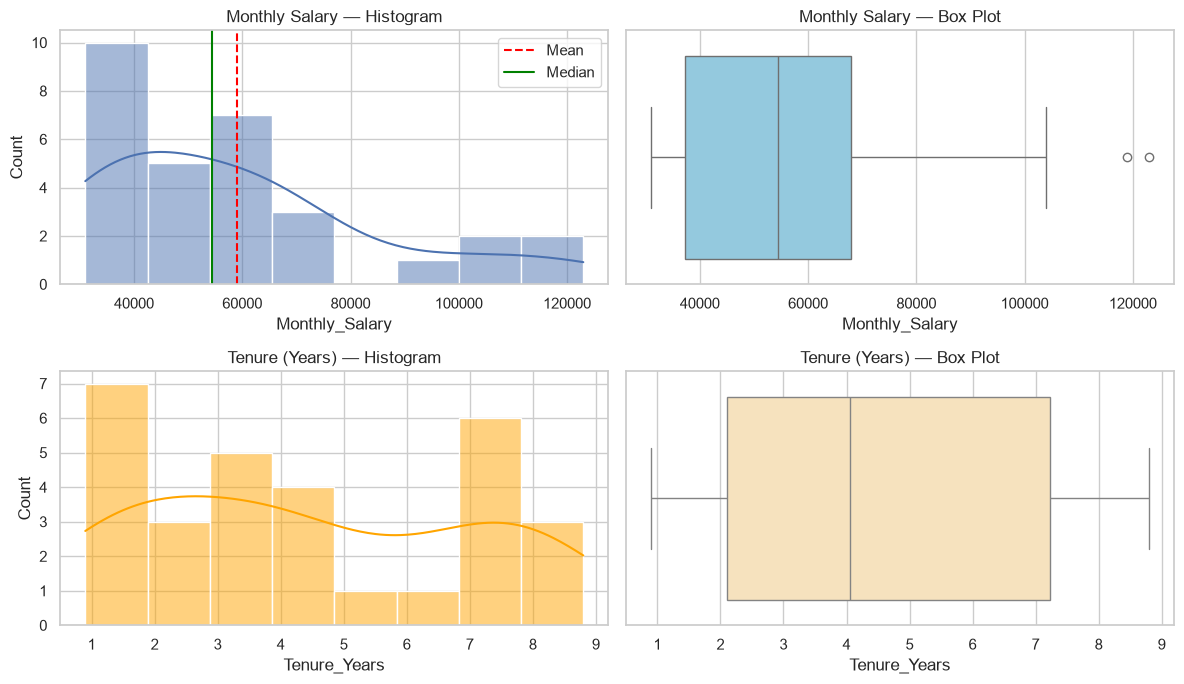

In [11]:
# Histogram + Box plot for both numeric columns
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

# --- Monthly_Salary ---
sns.histplot(data=df_clean, x="Monthly_Salary", bins=8, kde=True, ax=axes[0, 0])
axes[0, 0].axvline(sal.mean(), color="red", linestyle="--", label="Mean")
axes[0, 0].axvline(sal.median(), color="green", linestyle="-", label="Median")
axes[0, 0].set_title("Monthly Salary — Histogram")
axes[0, 0].legend()

sns.boxplot(data=df_clean, x="Monthly_Salary", ax=axes[0, 1], color="skyblue")
axes[0, 1].set_title("Monthly Salary — Box Plot")

# --- Tenure_Years ---
sns.histplot(data=df_clean, x="Tenure_Years", bins=8, kde=True, ax=axes[1, 0], color="orange")
axes[1, 0].set_title("Tenure (Years) — Histogram")

sns.boxplot(data=df_clean, x="Tenure_Years", ax=axes[1, 1], color="moccasin")
axes[1, 1].set_title("Tenure (Years) — Box Plot")

plt.tight_layout()
plt.show()

### How to read a box plot
```
   ●  ← outlier (dot outside the whiskers)
   ┬
   │  ← whisker (normal range)
 ┌─┴─┐ ← Q3 (75% of values are below this)
 │ ─ │ ← median
 └─┬─┘ ← Q1 (25% of values are below this)
   │
   ┴
```

### Your turn
1. Is the salary histogram symmetrical or does it have a tail? Which side?
2. Is the mean higher or lower than the median? What does that tell you?
3. Does any box plot show dots (outliers)?

# Step 6 — Univariate Analysis: Categorical Columns

For category columns we ask: *What groups exist? Which is biggest? Is it balanced?*

| Tool | Shows |
|------|-------|
| `value_counts()` | Count per group |
| `value_counts(normalize=True)` | Percentage per group |
| **Count plot** | The counts as bars |

In [12]:
# Counts and percentages
for col in ["Department", "Grade", "Employment_Type", "Gender"]:
    counts = df_clean[col].value_counts()
    percent = (df_clean[col].value_counts(normalize=True) * 100).round(1)
    display(pd.DataFrame({"count": counts, "percent": percent}))

,count,percent
Department,,
Sales,8,26.7
Operations,6,20.0
IT,6,20.0
Marketing,5,16.7
HR,3,10.0
Finance,2,6.7


,count,percent
Grade,,
G1,12,40.0
G2,10,33.3
G3,4,13.3
G4,4,13.3


,count,percent
Employment_Type,,
Full Time,20,66.7
Part Time,5,16.7
Contract,5,16.7


,count,percent
Gender,,
Male,17,56.7
Female,13,43.3


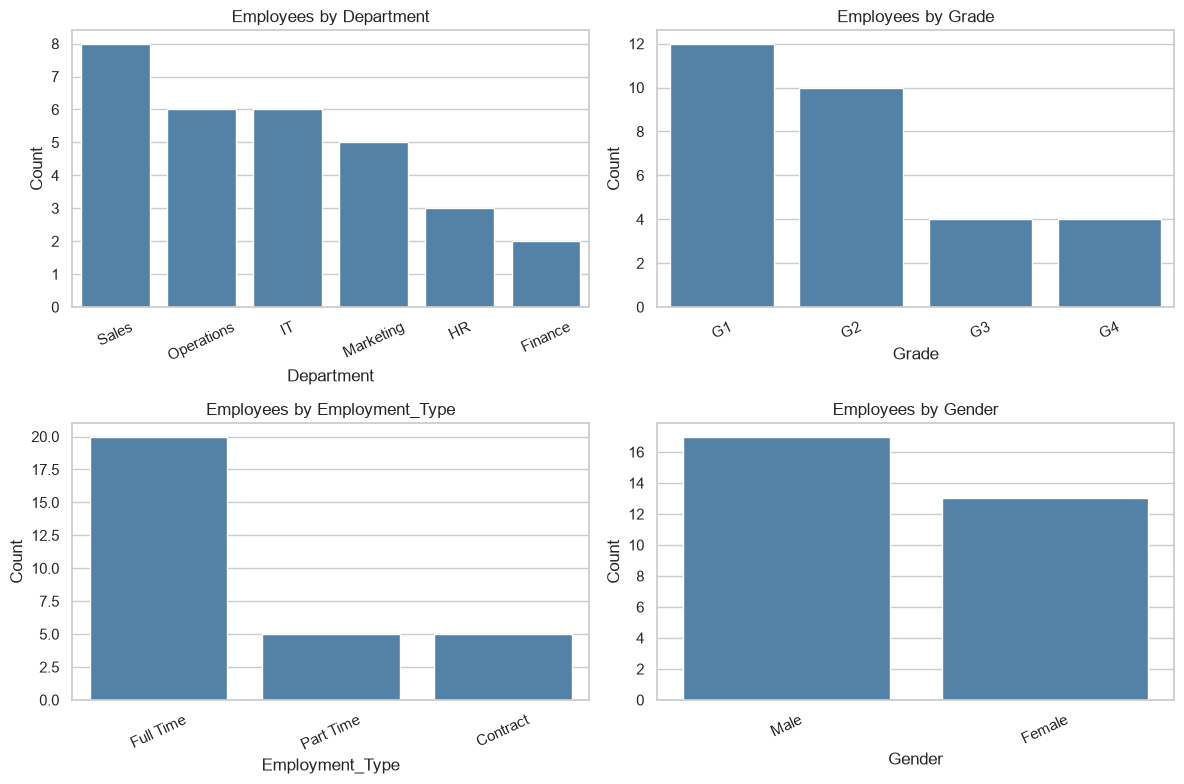

In [13]:
# Count plots (biggest group first)
cat_cols = ["Department", "Grade", "Employment_Type", "Gender"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, cat_cols):
    order = df_clean[col].value_counts().index        # sort bars big → small
    sns.countplot(data=df_clean, x=col, order=order, ax=ax, color="steelblue")
    ax.set_title(f"Employees by {col}")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

### Your turn
1. Which department has the most employees? The fewest?
2. What percentage of employees work Part Time?
3. Is the data balanced between Male and Female?

# Step 7 — Bivariate Analysis: Two Columns Together

**Bivariate = studying the relationship between TWO columns.**
The right tool depends on the column types:

| Column 1 | Column 2 | Best tool |
|----------|----------|-----------|
| Category | Number | `groupby().mean()`, bar chart, **box plot** |
| Number | Number | **Scatter plot**, correlation |
| Category | Category | `crosstab`, heatmap |

### 7.1 Category vs Number — *Does salary change with department / grade?*
**Excel equivalent:** Pivot Table (Rows = Department, Values = Average of Salary)

In [14]:
# Table: salary summary by department
dept_stats = (
    df_clean.groupby("Department")["Monthly_Salary"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(0)
    .sort_values("mean", ascending=False)
)
dept_stats

,count,mean,median,min,max
Department,,,,,
Finance,2,78000.0,78000.0,37000.0,119000.0
Marketing,5,75400.0,75000.0,45000.0,104000.0
IT,6,67000.0,57500.0,32000.0,123000.0
Sales,8,51000.0,59000.0,31000.0,65000.0
Operations,6,49833.0,45500.0,35000.0,72000.0
HR,3,43667.0,39000.0,34000.0,58000.0


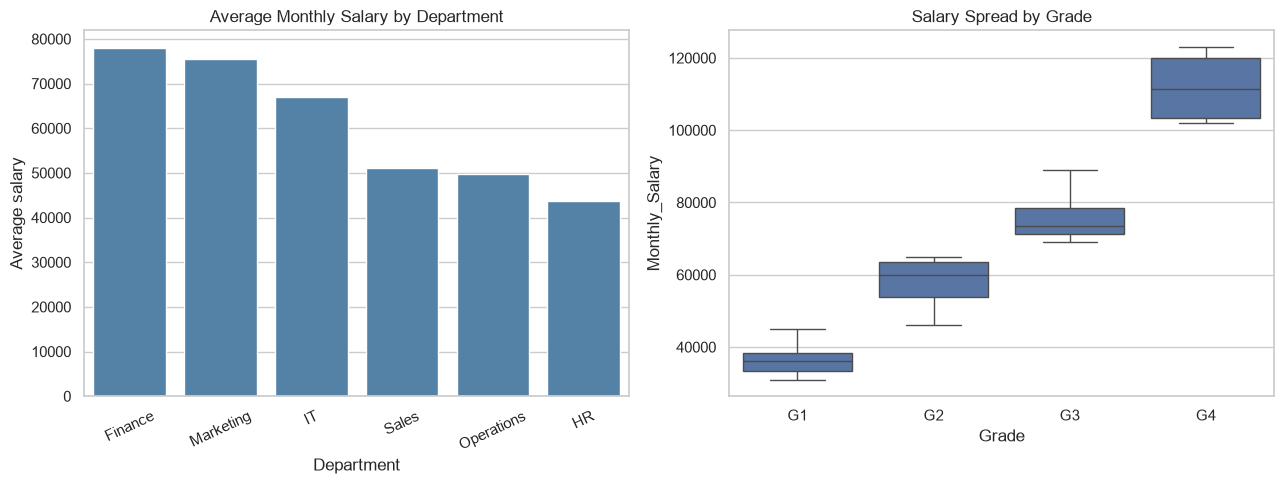

In [15]:
# Chart 1: average salary by department      Chart 2: salary spread by grade
grade_order = sorted(df_clean["Grade"].unique())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=dept_stats.reset_index(), x="Department", y="mean", color="steelblue", ax=axes[0])
axes[0].set_title("Average Monthly Salary by Department")
axes[0].set_ylabel("Average salary")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(data=df_clean, x="Grade", y="Monthly_Salary", order=grade_order, ax=axes[1])
axes[1].set_title("Salary Spread by Grade")

plt.tight_layout()
plt.show()

**Why a box plot is better than only the average:** two groups can have the same average but very different spreads.

### 7.2 Number vs Number — *Do people with more tenure earn more?*

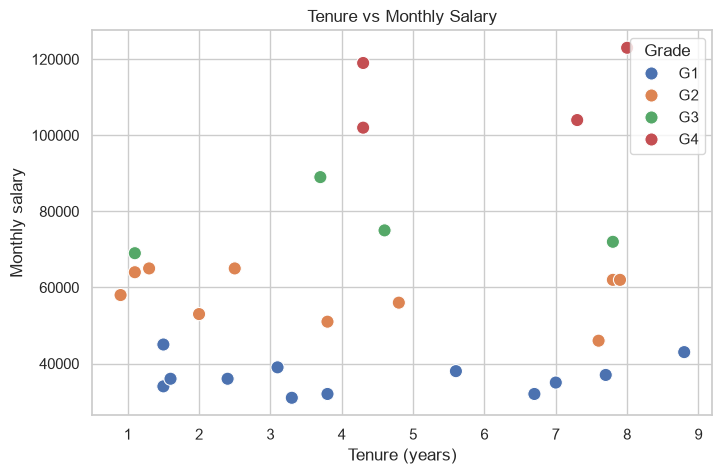

Correlation (Tenure vs Salary): 0.15


In [16]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean, x="Tenure_Years", y="Monthly_Salary",
    hue="Grade", hue_order=grade_order, s=90
)
plt.title("Tenure vs Monthly Salary")
plt.xlabel("Tenure (years)")
plt.ylabel("Monthly salary")
plt.show()

print("Correlation (Tenure vs Salary):", round(df_clean["Tenure_Years"].corr(df_clean["Monthly_Salary"]), 2))

**Reading a scatter plot:** points going up to the right → both increase together. A flat cloud → no relationship.
Notice the **colours** — often a third column (here *Grade*) explains the pattern better than the two axes alone. That is a first taste of **multivariate** analysis.

### 7.3 Category vs Category — *Which departments use which employment types?*
**Excel equivalent:** Pivot Table with Count.

Employment_Type,Contract,Full Time,Part Time
Department,,,
Finance,0,2,0
HR,0,3,0
IT,1,4,1
Marketing,1,3,1
Operations,1,4,1
Sales,2,4,2


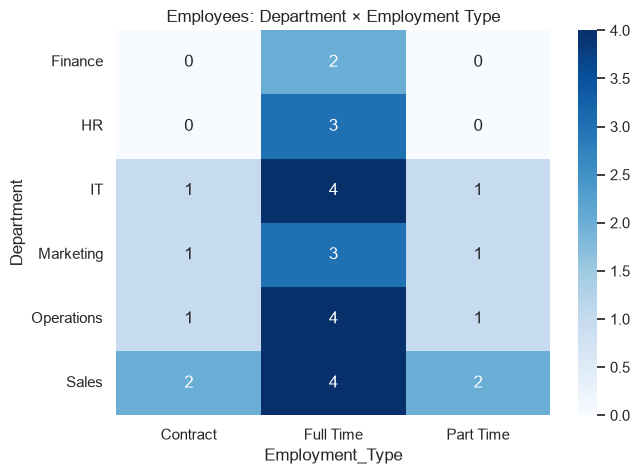

In [17]:
ct = pd.crosstab(df_clean["Department"], df_clean["Employment_Type"])
display(ct)

plt.figure(figsize=(7, 5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Employees: Department × Employment Type")
plt.show()

### Your turn
1. Which department has the highest average salary? Which has the lowest?
2. Does salary clearly increase from G1 to G4?
3. Is the *tenure vs salary* relationship strong, or does Grade matter more?
4. Which department has the most Part Time employees?

# Step 8 — Find Outliers

**Outlier = a value far away from the rest.**
It could be a **data error** (extra zero typed) or a **real extreme** (the CEO's salary). Never delete automatically — first investigate.

### The IQR rule
```
IQR   = Q3 − Q1
Lower = Q1 − 1.5 × IQR
Upper = Q3 + 1.5 × IQR
Anything outside [Lower, Upper] is an outlier.
```
(This is exactly what a box plot uses to draw dots.)

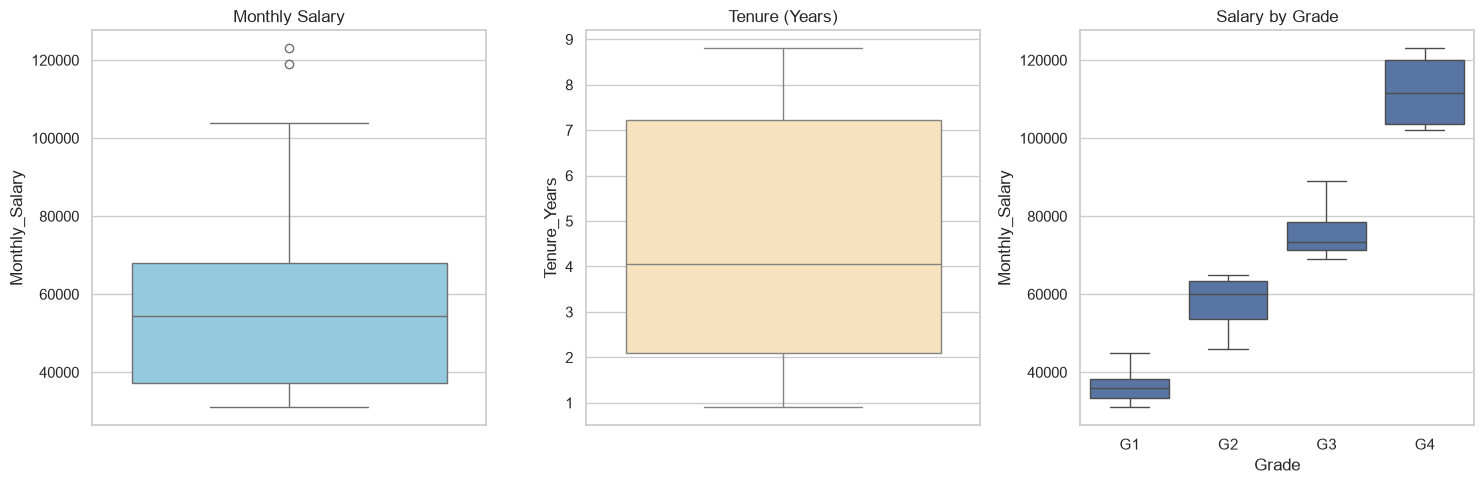

In [23]:
# Outliers: the dots outside the whiskers are the outliers
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(data=df_clean, y="Monthly_Salary", ax=axes[0], color="skyblue")
axes[0].set_title("Monthly Salary")

sns.boxplot(data=df_clean, y="Tenure_Years", ax=axes[1], color="moccasin")
axes[1].set_title("Tenure (Years)")

# Same salary, split by grade: is the dot still unusual inside its own group?
sns.boxplot(data=df_clean, x="Grade", y="Monthly_Salary",
            order=sorted(df_clean["Grade"].unique()), ax=axes[2])
axes[2].set_title("Salary by Grade")

plt.tight_layout()
plt.show()

**Investigate, then decide:**
- Look at the row — does the value make sense for that person's *Grade* and *Department*?
- A very high salary in the highest grade is probably **real** → keep it.
- A salary 10× higher than the same grade's others is probably an **error** → fix or remove it.

### Your turn
Is the outlier you found a mistake or a believable value? Explain using Grade and Department.

# Step 9 — Correlation

**Correlation** is one number that tells how strongly two numeric columns move together.

| Value | Meaning |
|-------|---------|
| **+1** | Perfect positive — when one goes up, the other goes up |
| **0** | No relationship |
| **−1** | Perfect negative — when one goes up, the other goes down |

Rough guide: `0.7 – 1.0` strong · `0.4 – 0.7` moderate · `below 0.4` weak.

> ⚠️ **Correlation is not causation.** Two things moving together does not prove one *causes* the other.

In [19]:
corr_cols = ["Monthly_Salary", "Tenure_Years", "Grade_Num"]
corr = df_clean[corr_cols].corr().round(2)
corr

,Monthly_Salary,Tenure_Years,Grade_Num
Monthly_Salary,1.00,0.15,0.96
Tenure_Years,0.15,1.00,0.15
Grade_Num,0.96,0.15,1.00


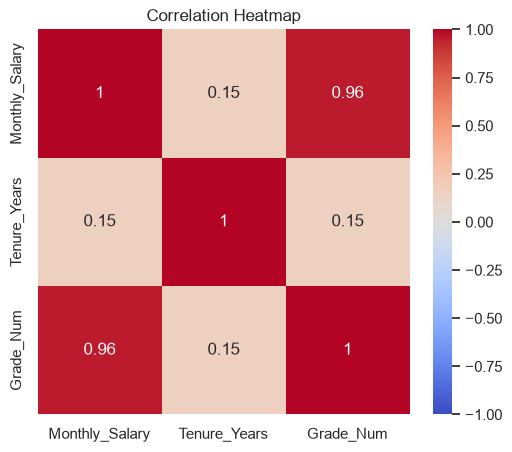

In [20]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlation Heatmap")
plt.show()

###  Your turn
1. Which column has the **strongest** correlation with `Monthly_Salary`?
2. Is `Tenure_Years` strongly correlated with salary? If not, which column explains salary better?

# Step 10 — Insights & Save the Clean Data

EDA is only useful if you **turn charts into sentences**. A good insight has 3 parts:

> **Finding** (what you saw) → **Evidence** (the number/chart) → **So what?** (what to do about it)

Let the code collect the key facts for us:

In [21]:
total_emp = len(df_clean)
top_dept = df_clean["Department"].value_counts().idxmax()
high_pay_dept = dept_stats.index[0]
low_pay_dept = dept_stats.index[-1]
part_time_pct = (df_clean["Employment_Type"] == "Part Time").mean() * 100
strongest = corr["Monthly_Salary"].drop("Monthly_Salary").abs().idxmax()
n_outliers = len(find_outliers(df_clean, "Monthly_Salary"))

print("=" * 55)
print("          EDA KEY FACTS — EMPLOYEE DATA")
print("=" * 55)
print(f"1. Total employees (after cleaning) : {total_emp}")
print(f"2. Largest department               : {top_dept}")
print(f"3. Average vs median salary         : {sal.mean():,.0f}  vs  {sal.median():,.0f}")
print(f"4. Highest-paid department (avg)    : {high_pay_dept}")
print(f"5. Lowest-paid department (avg)     : {low_pay_dept}")
print(f"6. Part-time employees              : {part_time_pct:.1f}%")
print(f"7. Column most linked to salary     : {strongest}")
print(f"8. Salary outliers found            : {n_outliers}")

Monthly_Salary: Q1=37,250.0  Q3=68,000.0  IQR=30,750.0  →  allowed range [-8,875.0, 114,125.0]
          EDA KEY FACTS — EMPLOYEE DATA
1. Total employees (after cleaning) : 30
2. Largest department               : Sales
3. Average vs median salary         : 59,100  vs  54,500
4. Highest-paid department (avg)    : Finance
5. Lowest-paid department (avg)     : HR
6. Part-time employees              : 16.7%
7. Column most linked to salary     : Grade_Num
8. Salary outliers found            : 2


###  Your turn — write 3 insights

| # | Finding | Evidence | So what? (recommendation) |
|---|---------|----------|---------------------------|
| 1 | | | |
| 2 | | | |
| 3 | | | |

*Example:* **Finding:** salary rises clearly with grade. **Evidence:** the box plot medians go up from G1 to G4 and `Grade_Num` has the strongest correlation. **So what?** Pay gaps inside the same grade deserve a review more than gaps between departments.

**Finally, save the clean data** so next time (dashboards, modelling, reports) you start from the clean file instead of repeating the cleaning.

In [22]:
df_clean.to_csv("Employee_Cleaned_EDA.csv", index=False)
# df_clean.to_excel("Employee_Cleaned_EDA.xlsx", index=False)

print("Saved! Final shape:", df_clean.shape)

Saved! Final shape: (30, 14)


# EDA Cheat Sheet

| I want to… | Code |
|------------|------|
| See first rows | `df.head()` |
| Rows × columns | `df.shape` |
| Types + missing overview | `df.info()` |
| Statistics for numbers | `df.describe()` |
| Statistics for text | `df.describe(exclude="number")` |
| Count missing values | `df.isna().sum()` |
| Count duplicates | `df.duplicated().sum()` |
| Unique values of a column | `df["col"].unique()` |
| Count per category | `df["col"].value_counts()` |
| Remove duplicates | `df.drop_duplicates(subset="ID")` |
| Fill missing values | `df["col"].fillna(value)` |
| Trim spaces | `df["col"].str.strip()` |
| Replace values | `df["col"].replace({"old": "new"})` |
| Average by group | `df.groupby("cat")["num"].mean()` |
| Two-category count table | `pd.crosstab(df["a"], df["b"])` |
| Correlation | `df[num_cols].corr()` |

| Question | Chart |
|----------|-------|
| How is a number spread? | Histogram, Box plot |
| How many in each category? | Count plot / Bar |
| Number across categories? | Box plot, Bar of averages |
| Two numbers related? | Scatter plot |
| Category × Category? | Heatmap of `crosstab` |
| All numbers related? | Correlation heatmap |

# Practice Exercises

Use `df_clean` and write your code in the cells below.

1. Show the **top 5 highest-paid** employees with their name, department and grade.
2. Find the **average salary by Gender**. Is the difference big? Can you say *why* from this table alone?
3. Make a **count plot of City** — which city has the most employees?
4. Make a **histogram of `Join_Year`**. In which years did the company hire the most?
5. Draw a **box plot of salary by Employment_Type**. Which type has the widest spread?
6. Create a column `Is_Manager` that is `True` when the employee's `Employee_ID` appears in the `Manager_ID` column (hint: `.isin()`), then compare the **average salary of managers vs non-managers**.

In [ ]:
# Exercise 1

In [ ]:
# Exercise 2

In [ ]:
# Exercise 3

In [ ]:
# Exercise 4

In [ ]:
# Exercise 5

In [ ]:
# Exercise 6